# Session 9 — Transfer Learning: Reusing a Trained Network

In Session 8 we trained a CNN on 10,000 digits. Photographs are harder, and collecting millions of labelled ones is out of reach for most projects. The usual answer is to start from a network that someone else has already trained on a very large photo collection, and adapt it.

We compare three ways of getting a flower classifier from 1,400 training photos, with everything else held fixed: a network trained from scratch, a pretrained network used as a fixed feature extractor, and a pretrained network that is then fine-tuned.

**By the end of the session you should be able to:**

1. describe a network as a backbone plus a small task head, and say what "frozen" means;
2. read a three-way comparison and say which differences are large enough to trust;
3. explain why the held-out photos must be chosen once, by file, and not reshuffled.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `pillow`, `torch` and `torchvision`. The first run downloads the flower photos (229 MB) into `~/.cache/ai_journey` and the MobileNetV2 weights (14 MB). The saved outputs came from a laptop GPU, where the three training runs took about four minutes. On a CPU, expect much longer, mostly for the from-scratch run; lower `PER_CLASS` to 100 for a quick pass. Your numbers may differ from the ones quoted in the text.

## 1. The data

The download holds 3,670 photos of five kinds of flower. To keep the run short we take 400 of each, 2,000 photos in all, shrunk to 128×128 pixels.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # lets the GPU repeat a run exactly

import copy
import time
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import models
from torchvision.transforms import v2
from torchvision.datasets.utils import download_and_extract_archive
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

SEED, IMAGE_SIZE, PER_CLASS = 42, 128, 400
DATA = pathlib.Path.home() / ".cache" / "ai_journey"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.use_deterministic_algorithms(True)

URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = DATA / "flower_photos"
if not data_dir.exists():
    download_and_extract_archive(URL, DATA)
all_files = sorted(data_dir.glob("**/*.jpg"))
classes = sorted({f.parent.name for f in all_files})

rng = np.random.default_rng(SEED)
paths, labels = [], []
for k, name in enumerate(classes):
    files = [f for f in all_files if f.parent.name == name]
    chosen = [files[i] for i in rng.permutation(len(files))[:PER_CLASS]]
    paths += [str(f) for f in chosen]
    labels += [k] * len(chosen)
paths, labels = np.array(paths), np.array(labels)

print(f"{len(all_files)} photos in the download, {len(paths)} used ({PER_CLASS} per class).  Classes: {classes}")

3670 photos in the download, 2000 used (400 per class).  Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## 2. One split, made by file

The split is made on the list of file names, once: 70% training (1,400 photos), 15% validation (300) and 15% test (300). Each photo's job is fixed for the whole notebook.

This matters because a common way to build the sets from image folders is to let the library shuffle on every pass and carve the validation and test sets out of the same stream. Then each pass hands out different photos, and validation and test overlap, so the test score is no longer a fair measure. Splitting by file avoids it. Only the training data is shuffled at training time; validation and test keep a fixed order.

The three jobs are the same as in Session 4: training updates the weights, validation decides when to stop, and test is scored at the end.

train 1400, validation 300, test 300
Photos shared between training and test: 0   between validation and test: 0


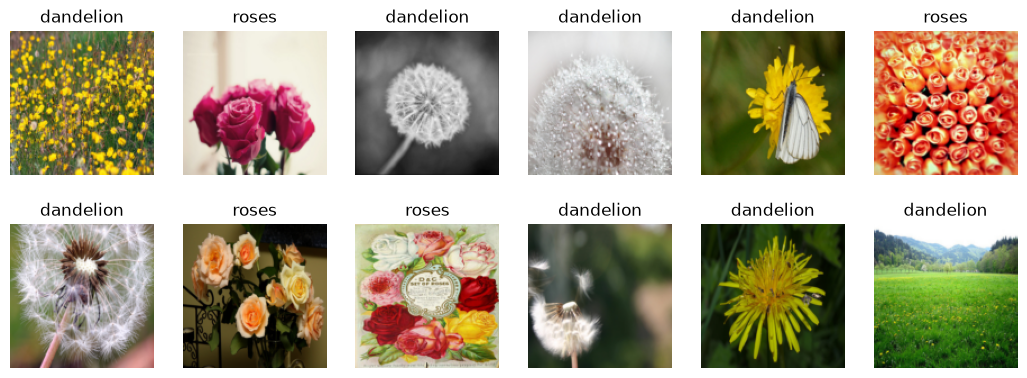

In [2]:
# Split the list of FILES, once. Each photo belongs to exactly one set for the whole notebook.
p_train, p_rest, y_train, y_rest = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED)

print(f"train {len(p_train)}, validation {len(p_val)}, test {len(p_test)}")
print("Photos shared between training and test:", len(set(p_train) & set(p_test)), "  between validation and test:", len(set(p_val) & set(p_test)))


def load(paths):
    """Read each photo, shrink it to 128 x 128 and stack them: one tensor of shape (photos, 3 colour channels, 128, 128)."""
    images = [np.asarray(Image.open(p).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)) for p in paths]
    return torch.from_numpy(np.stack(images)).permute(0, 3, 1, 2)


x_train, x_val, x_test = load(p_train), load(p_val), load(p_test)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for ax, image, label in zip(axes.ravel(), x_train, y_train):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[int(label)])
    ax.axis("off")
plt.show()

The printed check shows zero photos shared between the sets.

> **Pause:** the next cell makes random changes to a training photo: flips it left to right, rotates it a little, zooms in or out. Which of these changes would be wrong for a dataset of handwritten digits like Session 8's?
>
> - **A.** Flipping left to right.
> - **B.** Rotating a little.
> - **C.** Zooming in or out.
> - **D.** All three are fine for digits.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**A.** A flipped digit is not a digit, and rotating a 6 far enough makes it look like a 9. Small rotations and zooms keep the label. Augmentation is a claim about which changes don't matter for the task.

</details>

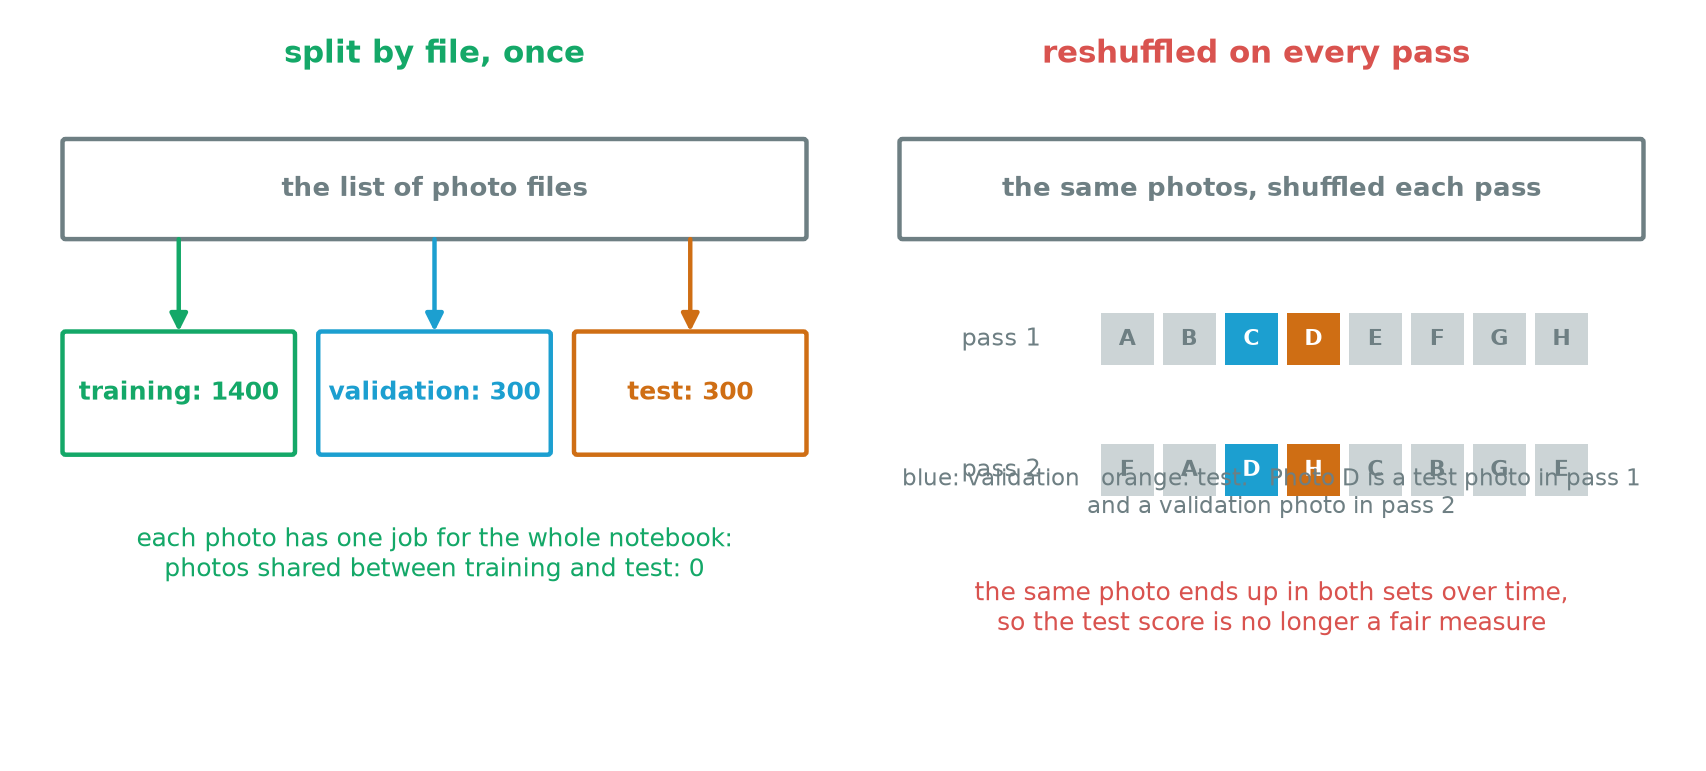

*Figure 9.1 — Two ways to build the sets. Splitting the list of file names once gives each photo one job (1400 training, 300 validation, 300 test, none shared). Reshuffling the stream on every pass can hand the same photo to validation on one pass and to test on another, so the test score stops being a fair measure.*

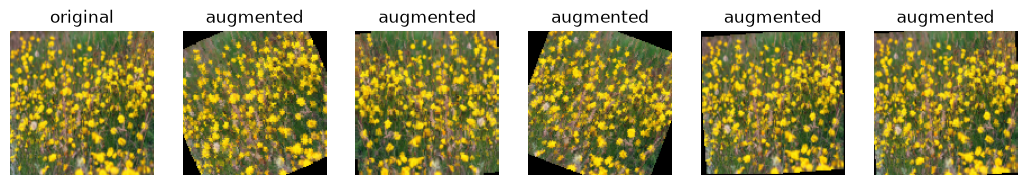

In [3]:
augment = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomRotation(29), v2.RandomAffine(degrees=0, scale=(0.9, 1.1))])  # flip; rotate up to 29 degrees; zoom up to 10%

torch.manual_seed(SEED)
sample = x_train[0]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
axes[0].imshow(sample.permute(1, 2, 0))
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(sample).permute(1, 2, 0))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

## 3. Augmentation: extra views of the same photo

With few photos, we show the network randomly altered copies during training: flipped left to right, rotated by up to 29 degrees, zoomed in or out by up to 10%. The six pictures show one photo and five random versions; the black corners are where a rotated photo no longer covers the square. These changes keep the label (a flipped daisy is still a daisy), so they are safe for flowers. They are not safe for every task: flipping a photo of text changes the text, and rotating a 6 far enough can make it look like a 9, while flipping a digit gives a shape that isn't a digit at all. Augmentation is a claim about which changes don't matter for the task.

In [4]:
WEIGHTS = models.MobileNet_V2_Weights.IMAGENET1K_V1
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
loss_fn = nn.CrossEntropyLoss()


class FlowerNet(nn.Module):
    """Backbone: MobileNetV2's convolution layers. Head: average each feature map to one number, dropout, one linear layer."""

    def __init__(self, pretrained):
        super().__init__()
        torch.manual_seed(SEED)
        self.pretrained = pretrained
        self.backbone = models.mobilenet_v2(weights=WEIGHTS if pretrained else None).features
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(1280, len(classes)))

    def forward(self, images):  # images: whole numbers 0-255, shape (batch, 3, 128, 128)
        x = (images.float() / 255 - MEAN.to(images.device)) / STD.to(images.device)  # the scaling the ImageNet weights expect
        return self.head(self.backbone(x).mean(dim=(2, 3)))

    def train(self, mode=True):
        super().train(mode)
        if self.pretrained:
            self.backbone.eval()  # keep ImageNet's batch-normalisation statistics (see Going deeper)
        return self


def trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def evaluate(model, x, y):
    model.eval()
    with torch.no_grad():
        scores = torch.cat([model(batch.to(DEVICE)).cpu() for batch in x.split(100)])
    return loss_fn(scores, y).item(), (scores.argmax(dim=1) == y).float().mean().item(), scores.argmax(dim=1)


def fit(model, lr, epochs, patience=5):
    """Adam, batches of 32 augmented photos; stop when validation loss hasn't improved for 5 epochs and keep the best weights."""
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    order = torch.Generator().manual_seed(SEED)
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    started = time.time()
    for epoch in range(epochs):
        model.train()
        total_loss, correct = 0.0, 0
        for batch in torch.randperm(len(x_train), generator=order).split(32):
            images, targets = torch.stack([augment(image) for image in x_train[batch]]).to(DEVICE), y_train[batch].to(DEVICE)
            scores = model(images)
            loss = loss_fn(scores, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)
            correct += (scores.argmax(dim=1) == targets).sum().item()
        val_loss, val_accuracy, _ = evaluate(model, x_val, y_val)
        for key, value in zip(history, [total_loss / len(x_train), correct / len(x_train), val_loss, val_accuracy]):
            history[key].append(value)
        if val_loss == min(history["val_loss"]):
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - int(np.argmin(history["val_loss"])) >= patience:
            break
    model.load_state_dict(best_weights)
    return history, time.time() - started


def report(name, history, seconds):
    print(f"{name}: {len(history['loss'])} epochs, {seconds:.0f} s, best validation accuracy {max(history['val_accuracy']):.3f}")
    print("  validation accuracy by epoch:", np.round(history["val_accuracy"], 3).tolist())
    print("  validation loss by epoch:    ", np.round(history["val_loss"], 2).tolist())


runs = {}

## 4. Backbone and head

All three models have the same shape. The **backbone** is MobileNetV2, a network of about 2.2 million parameters, which turns an image into a short list of numbers describing it. The **head** is a small layer on top that turns those numbers into five flower probabilities. The three runs differ only in the backbone's starting weights and in which parts are allowed to change.

*Helper code: presenters can skip the next cell on screen.* It defines the model (`FlowerNet`), a function that counts trainable parameters, and one training routine used by all three runs: the same split, augmentation and early-stopping rule (stop when validation loss hasn't improved for 5 epochs, and keep the best weights). The loop inside `fit` is Session 7's, with a fresh set of augmented photos in every batch. "Frozen" has a precise meaning in PyTorch: a parameter with `requires_grad = False` gets no gradient, so the optimiser never changes it.

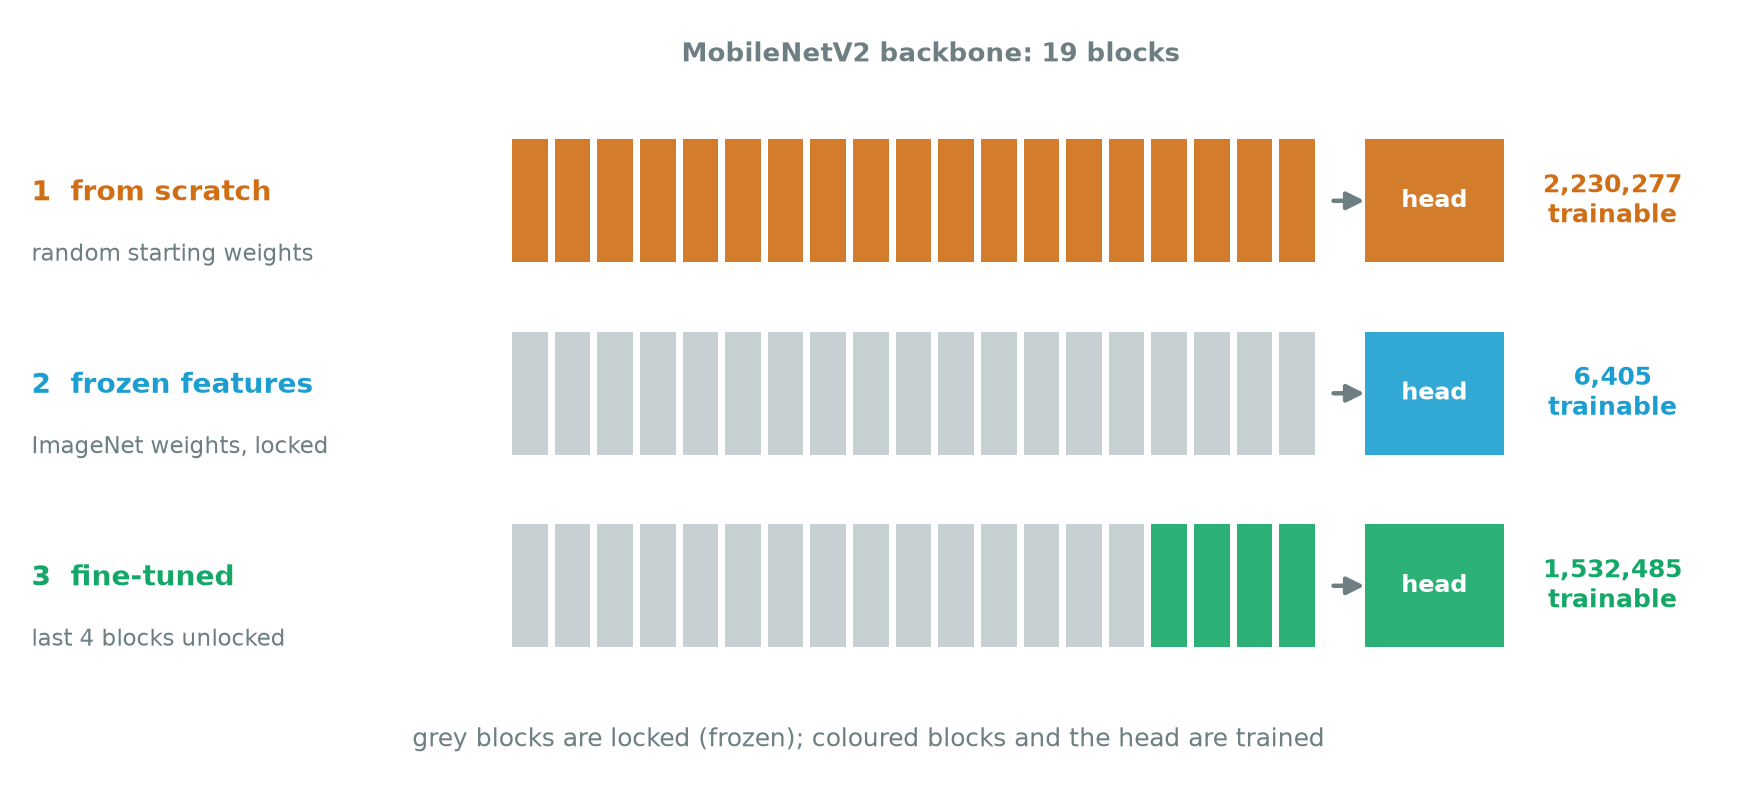

*Figure 9.2 — The same backbone and head in three versions. From scratch trains everything (2,230,277 parameters); frozen features locks the pretrained backbone and trains only the head (6,405); fine-tuning unlocks the last 4 of the 19 blocks as well (1,532,485).*

In [5]:
# 1. From scratch: the same architecture, random starting weights, every layer trained.
scratch = FlowerNet(pretrained=False).to(DEVICE)
history, seconds = fit(scratch, 1e-3, epochs=20)
runs["1. from scratch"] = dict(model=scratch, history=history, seconds=seconds, trainable=trainable_parameters(scratch))
report("from scratch", history, seconds)

from scratch: 20 epochs, 139 s, best validation accuracy 0.697
  validation accuracy by epoch: [0.2, 0.427, 0.547, 0.567, 0.427, 0.543, 0.553, 0.597, 0.54, 0.62, 0.567, 0.62, 0.597, 0.653, 0.65, 0.653, 0.613, 0.63, 0.663, 0.697]
  validation loss by epoch:     [1.92, 1.71, 1.1, 1.09, 1.36, 1.13, 1.1, 1.02, 1.2, 1.02, 1.17, 1.0, 1.05, 0.95, 0.98, 0.97, 0.96, 1.03, 0.92, 0.86]


**Run 1: from scratch.** The backbone starts from random weights and every layer is trained, 2,230,277 parameters in all. It trained for the full 20 epochs, which took 139 seconds, and reached its best validation accuracy of 0.697 in the last epoch. Early stopping never triggered: the validation loss was still falling at the end.

In [6]:
# 2. Frozen features: pretrained backbone fixed, only the new classification layer is trained.
frozen = FlowerNet(pretrained=True).to(DEVICE)
for p in frozen.backbone.parameters():
    p.requires_grad = False
history, seconds = fit(frozen, 1e-3, epochs=10)
runs["2. frozen features"] = dict(model=frozen, history=history, seconds=seconds, trainable=trainable_parameters(frozen))
report("frozen features", history, seconds)

frozen features: 10 epochs, 55 s, best validation accuracy 0.843
  validation accuracy by epoch: [0.75, 0.79, 0.79, 0.8, 0.81, 0.817, 0.843, 0.81, 0.833, 0.807]
  validation loss by epoch:     [0.67, 0.55, 0.52, 0.56, 0.49, 0.48, 0.46, 0.45, 0.47, 0.49]


**Run 2: frozen features.** The backbone starts from weights trained on ImageNet, a collection of over a million photos in a thousand categories, and is frozen. Only the head trains, which is 6,405 parameters (1,280 features × 5 classes + 5 biases). It ran for 10 epochs in 55 seconds and reached a best validation accuracy of 0.843, at epoch 7.

ImageNet is where deep networks took over computer vision. In 2012 a deep CNN called AlexNet won the ImageNet image-classification contest with a top-5 error of 15.3%, against 26.2% for the next entry, and networks pretrained on ImageNet have been a common starting point for image tasks since.

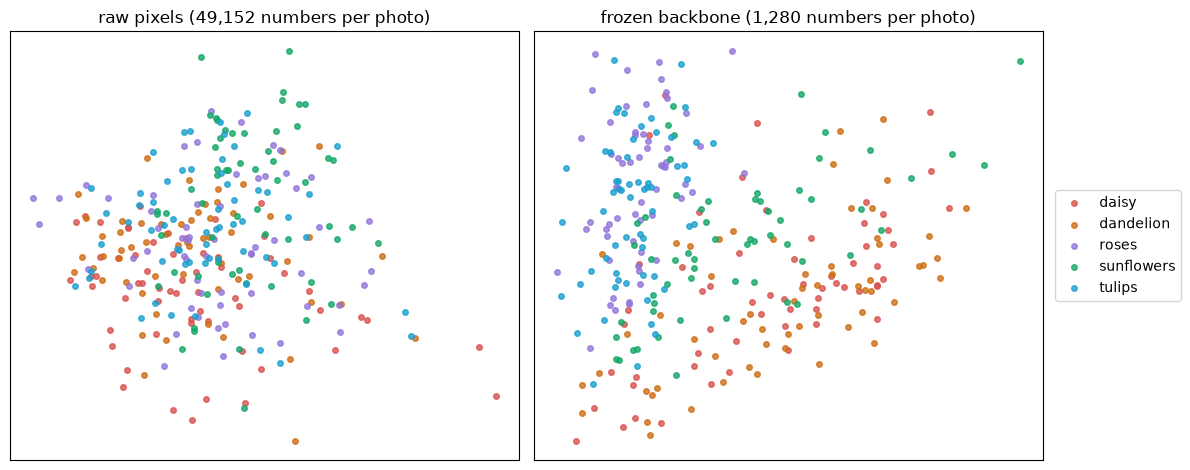

300 test photos; features per photo: 1,280


In [7]:
# Figure 9.3: PCA of the test photos, from raw pixels and from the frozen backbone's features
from sklearn.decomposition import PCA
frozen.eval()
with torch.no_grad():
    scaled = (x_test.float() / 255 - MEAN) / STD
    feats = torch.cat([frozen.backbone(b.to(DEVICE)).mean(dim=(2, 3)).cpu() for b in scaled.split(100)]).numpy()      # (300, 1280)
pix = x_test.reshape(len(x_test), -1).float().numpy() / 255
colors = ["#D9534F", "#CF6E14", "#9276DA", "#14A868", "#1C9FD0"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, data, title in zip(axes, [pix, feats], [f"raw pixels ({pix.shape[1]:,} numbers per photo)", f"frozen backbone ({feats.shape[1]:,} numbers per photo)"]):
    emb = PCA(n_components=2).fit_transform(data)
    for k, name in enumerate(classes): ax.scatter(*emb[y_test.numpy() == k].T, s=16, color=colors[k], label=name, alpha=0.8)
    ax.set(title=title, xticks=[], yticks=[])
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()
print(f"{len(feats)} test photos; features per photo: {feats.shape[1]:,}")

*Figure 9.3 — What the frozen backbone sees. Each dot is one of the 300 test photos, coloured by flower and flattened to two dimensions by PCA. Left: from the raw pixels, the colours are mixed together. Right: from the 1,280 numbers the frozen ImageNet backbone computes per photo, the kinds start to separate, with tulips and roses mostly on the left and daisies and dandelions mostly on the right, although two dimensions still leave a lot of overlap. No flower label was used to build either map.*

In [8]:
# 3. Fine-tuning: continue from run 2 (a copy, so run 2 keeps its own weights), unfreeze the last 4 of the backbone's 19 blocks,
#    and use a much smaller learning rate.
fine = copy.deepcopy(frozen)
for p in fine.backbone[-4:].parameters():
    p.requires_grad = True
history, seconds = fit(fine, 1e-5, epochs=10)
runs["3. fine-tuned"] = dict(model=fine, history=history, seconds=seconds + runs["2. frozen features"]["seconds"], trainable=trainable_parameters(fine))
report("fine-tuning", history, seconds)

fine-tuning: 10 epochs, 57 s, best validation accuracy 0.860
  validation accuracy by epoch: [0.83, 0.83, 0.837, 0.86, 0.843, 0.853, 0.857, 0.853, 0.847, 0.86]
  validation loss by epoch:     [0.43, 0.42, 0.42, 0.41, 0.4, 0.39, 0.37, 0.37, 0.4, 0.38]


**Run 3: fine-tuning.** We start from a copy of run 2, unfreeze the last 4 of the backbone's 19 blocks (1,532,485 trainable parameters), and train with a learning rate 100 times smaller (0.00001 instead of 0.001), so the pretrained features are nudged and not overwritten. It trained for all 10 epochs (57 seconds) and reached a best validation accuracy of 0.860.

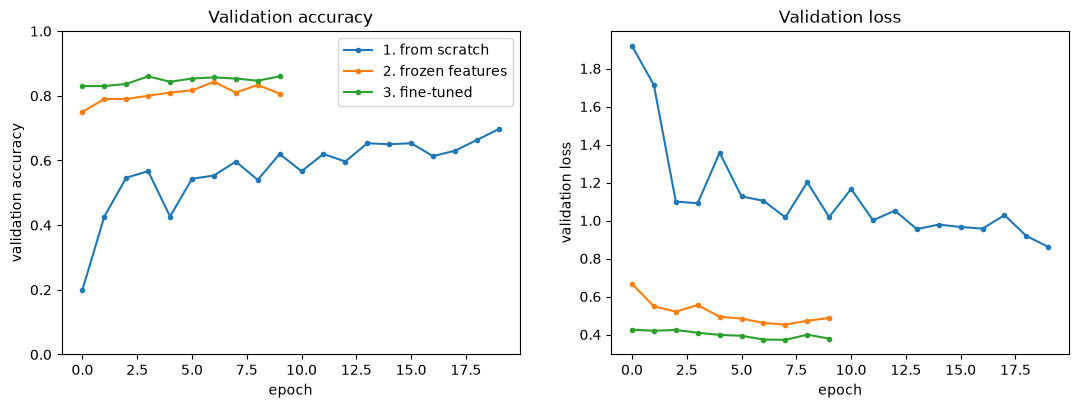

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for name, run in runs.items():
    axes[0].plot(run["history"]["val_accuracy"], marker="o", markersize=3, label=name)
    axes[1].plot(run["history"]["val_loss"], marker="o", markersize=3, label=name)
axes[0].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy", ylim=(0, 1))
axes[1].set(xlabel="epoch", ylabel="validation loss", title="Validation loss")
axes[0].legend()
plt.show()

## 5. The three runs side by side

> **Pause:** before looking at the table, order the three strategies by test accuracy. How big do you expect the gaps to be?
>
> - **A.** Scratch, then frozen, then fine-tuned, with a large first gap and a small second gap.
> - **B.** Scratch, then frozen, then fine-tuned, with all gaps about a point.
> - **C.** Fine-tuned, then frozen, then scratch, because it has more trainable parameters.
> - **D.** All three within a point of each other.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**A.** Test accuracy is 0.710 from scratch, 0.850 with frozen features and 0.883 fine-tuned: pretraining gives 14 points, fine-tuning a few more. The frozen model trains 6,405 parameters against 2,230,277 from scratch.

</details>

The curves show how different the starting points are. The from-scratch network (blue) begins at chance, 0.20 accuracy, and climbs unevenly to 0.697, with a validation loss that falls from 1.92 to 0.86 with bumps along the way (1.36 at epoch 5, 1.2 at epoch 9). The frozen model (orange) is at 0.75 after its first epoch. The fine-tuned model (green) starts where run 2 ended, at 0.83, and its validation loss falls slowly, from 0.43 to 0.37.

In [10]:
rows = []
for name, run in runs.items():
    model = run["model"]
    rows.append({"strategy": name, "trainable parameters": f"{run['trainable']:,}", "epochs": len(run["history"]["loss"]), "training time (s)": round(run["seconds"]),
                 "validation accuracy": round(evaluate(model, x_val, y_val)[1], 3), "test accuracy": round(evaluate(model, x_test, y_test)[1], 3)})
pd.DataFrame(rows).set_index("strategy")

,trainable parameters,epochs,training time (s),validation accuracy,test accuracy
strategy,,,,,
1. from scratch,"2,230,277",20,139,0.697,0.710
2. frozen features,"6,405",10,55,0.810,0.850
3. fine-tuned,"1,532,485",10,111,0.853,0.883


| strategy | trainable parameters | epochs | time (s) | validation | test |
|---|---:|---:|---:|---:|---:|
| 1. from scratch | 2,230,277 | 20 | 139 | 0.697 | 0.710 |
| 2. frozen features | 6,405 | 10 | 55 | 0.810 | 0.850 |
| 3. fine-tuned | 1,532,485 | 10 | 111 | 0.853 | 0.883 |

(The table scores the weights kept by early stopping, the epoch with the lowest validation *loss*, so the validation accuracy can sit below the best epoch printed earlier: 0.810 against 0.843 for run 2. The time for run 3 includes run 2's 55 seconds.)

**Pretraining is the large effect.** Starting from ImageNet weights lifts the test accuracy from 0.710 to 0.850, 14 points, while training 348 times fewer parameters in less than half the time. All of that comes from the weights: the architecture, the data and the augmentation are the same.

**Fine-tuning added a smaller gain.** It raised validation accuracy from 0.810 to 0.853 and test accuracy from 0.850 to 0.883, which is 10 more of the 300 test photos right. Both sets moved the same way and its validation loss was still falling at the end, so the gain is probably real, but it comes from one run with one seed: with 300 test photos, one photo is worth 0.3 points, and a gap of a point or two would not be trustworthy either way. Fine-tuning pays more when the new photos differ from ImageNet's, or when there is more data.

To keep the comparison fair, a pretrained model counts as pretrained even if every layer is trainable, and the three runs must share the split, the image size, the augmentation, the stopping rule and the seed. Here they do. Each run is also scored with its own weights: run 3 trains a copy of run 2, so the table's row for run 2 is still the frozen model.

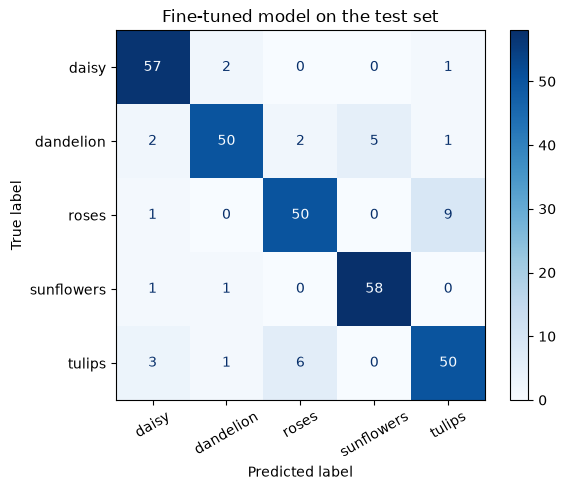

265 of 300 test photos correct. Rows: true class, columns: predicted.
            daisy  dandelion  roses  sunflowers  tulips
daisy          57          2      0           0       1
dandelion       2         50      2           5       1
roses           1          0     50           0       9
sunflowers      1          1      0          58       0
tulips          3          1      6           0      50


In [11]:
final = runs["3. fine-tuned"]["model"]
test_predictions = evaluate(final, x_test, y_test)[2]
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, display_labels=classes, cmap="Blues", xticks_rotation=30)
plt.title("Fine-tuned model on the test set")
plt.show()
print(f"{(test_predictions == y_test).sum().item()} of {len(y_test)} test photos correct. Rows: true class, columns: predicted.")
print(pd.DataFrame(confusion_matrix(y_test, test_predictions), index=classes, columns=classes).to_string())

The confusion matrix for the fine-tuned model shows 265 of 300 test photos correct. The biggest confusion is between roses and tulips: 9 roses were called tulips and 6 tulips were called roses. Both are often red or pink flowers photographed in a garden, and the model was given only 128×128 pixels. Dandelions come next, with 5 called sunflowers: both are yellow. Sunflowers and daisies are the most reliable, with 58 and 57 of 60 correct.

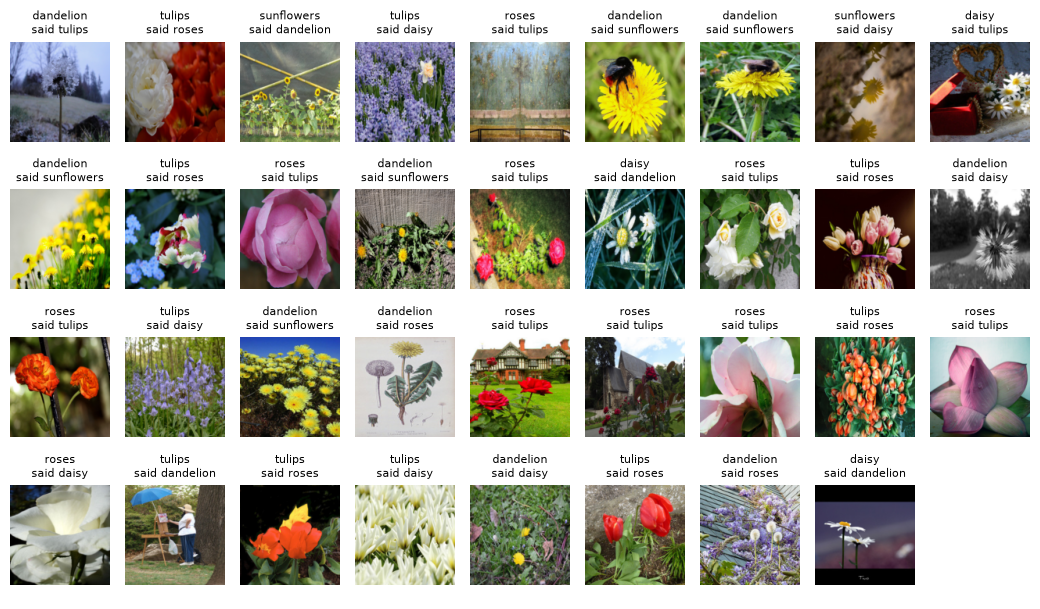

35 of 300 test photos are wrong


In [12]:
# Figure 9.4: all the test photos the fine-tuned model got wrong
bad = (test_predictions != y_test).nonzero().ravel().tolist()
cols = 9
fig, axes = plt.subplots(-(-len(bad) // cols), cols, figsize=(10.5, 1.55 * -(-len(bad) // cols)))
for ax in axes.ravel(): ax.axis("off")
for ax, i in zip(axes.ravel(), bad):
    ax.imshow(x_test[i].permute(1, 2, 0)); ax.set_title(f"{classes[y_test[i]]}\nsaid {classes[test_predictions[i]]}", fontsize=8)
plt.tight_layout(); plt.show()
print(f"{len(bad)} of {len(y_test)} test photos are wrong")

*Figure 9.4 — Every test photo the fine-tuned model got wrong, with its true flower and what the model said. The 35 mistakes include the rose and tulip photos the text discusses; several are photos where the flower is small, partly hidden or not the main subject.*

## What to take away

- Start from a pretrained backbone when you have few labelled images. Here that was worth 14 points of accuracy.
- Train the head first with the backbone frozen. Try fine-tuning next, with a small learning rate, and keep it only if validation shows a gain. Here it added about 3 points on both validation and test.
- Split by file, once, and keep the held-out sets in a fixed order.
- Change one thing between runs, report training time and parameter counts, and score the test set once per final model.

> **Callback · Advanced Session 13.** The same flower photos come back there: CLIP classifies them zero-shot, with no training on flowers, at 0.973, against 0.850 and 0.883 for the networks of this session.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The two pieces

A classifier can be written as $\hat y=g_\phi(f_\theta(x))$, where $f_\theta$ is the backbone (the image-to-features part) and $g_\phi$ is the head. Feature extraction fits only $\phi$ with $\theta$ fixed at its pretrained value. Fine-tuning fits both, starting from the pretrained $\theta$ and the head trained earlier.

## Why a smaller learning rate, and why the head first

A new head starts with random weights, so its early gradients are large and unhelpful. If the backbone were trainable from the start, those gradients would change good features to suit a bad head. Large updates to a pretrained network can erase what it learned, which is sometimes called catastrophic forgetting. Training the head first, then fine-tuning with a learning rate of $10^{-5}$, avoids this.

## Batch normalisation

MobileNetV2 contains batch-normalisation layers (Session 7's Going deeper), which keep running averages of each activation's mean and spread. In the pretrained runs, `FlowerNet.train` puts the backbone in evaluation mode, so these averages stay as they were learned on ImageNet, including during fine-tuning; only the weights the optimiser is allowed to change move. Without that line, `model.train()` would let 1,400 flower photos overwrite ImageNet's statistics while the frozen weights stayed put. In the from-scratch run the averages have to be learned from our own photos, so its batch normalisation runs normally.

## Fair comparisons

A comparison of strategies should hold fixed the split, image size, preprocessing, augmentation, metric, stopping rule and seed, and report the compute spent. Repeating each run with several seeds would show how much of a one-point difference is luck; we ran each once.